## 2.1 Wrangling dan EDA (Maks. skor: 45)

In [1]:
import sys
import pandas as pd
import scipy
import sklearn
import networkx as nx
import matplotlib

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NetworkX:", nx.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: c:\Users\LENOVO\Documents\UTS GSD\myvenv\Scripts\python.exe
Pandas: 3.0.6
SciPy: 1.18.1
Scikit-learn: 1.9.1
NetworkX: 3.7
Matplotlib: 3.11.2


UTS Graf Sains Data — Analisis RetailRocket

1. Pendahuluan

Analisis ini menggunakan dataset interaksi pengguna RetailRocket untuk mempelajari struktur graf antara *Visitor* dan *Item*. Tahapan analisis meliputi persiapan data berdasarkan periode waktu, eksplorasi komposisi subgraf, pembentukan Vector Space Model (VSM), visualisasi graf menggunakan NetworkX, perbandingan proyeksi graf, dan perhitungan kemiripan (*similarity*).

2. Persiapan Lingkungan

Analisis dilakukan menggunakan Python di Jupyter Notebook pada VS Code. Library yang digunakan mencakup Pandas untuk pengolahan data, SciPy untuk representasi matriks sparse, scikit-learn untuk analisis kemiripan, NetworkX untuk pemodelan graf, Matplotlib untuk visualisasi, dan Neo4j Python Driver untuk mengakses basis data graf.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 6)

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


In [19]:
import pandas as pd
from pathlib import Path

# Lokasi dataset asli
CSV_PATH = Path(
    r"C:\Users\LENOVO\Documents\UTS GSD\ecommerce-dataset\events.csv"
)

# Folder penyimpanan hasil
OUTPUT_DIR = Path(r"C:\Users\LENOVO\Documents\UTS GSD")

# Baca dataset asli
df = pd.read_csv(CSV_PATH)

# Konversi Unix timestamp milidetik ke waktu UTC
df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", utc=True
)

# Filter P1: 3 Mei–24 Juli 2015
train_df = df[
    (df["datetime"] >= "2015-05-03 00:00:00+00:00") &
    (df["datetime"] <  "2015-07-25 00:00:00+00:00")
].copy()

# Filter P2: 25 Juli–18 September 2015
test_df = df[
    (df["datetime"] >= "2015-07-25 00:00:00+00:00") &
    (df["datetime"] <  "2015-09-19 00:00:00+00:00")
].copy()

# Hapus kolom datetime tambahan; timestamp asli tetap dipertahankan
train_df.drop(columns=["datetime"], inplace=True)
test_df.drop(columns=["datetime"], inplace=True)

# Simpan sebagai file baru
train_path = OUTPUT_DIR / "retailrocket_train_new.csv"
test_path = OUTPUT_DIR / "retailrocket_test_new.csv"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

# Tampilkan ringkasan hasil
print("P1 Training:", f"{len(train_df):,}", "baris")
print("P2 Testing:", f"{len(test_df):,}", "baris")
print("\nKolom:", train_df.columns.tolist())
print("File training:", train_path)
print("File testing:", test_path)
print("\nEkspor CSV baru selesai.")


P1 Training: 1,725,562 baris
P2 Testing: 1,030,539 baris

Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
File training: C:\Users\LENOVO\Documents\UTS GSD\retailrocket_train_new.csv
File testing: C:\Users\LENOVO\Documents\UTS GSD\retailrocket_test_new.csv

Ekspor CSV baru selesai.


In [20]:

# Ringkasan dataset training dan testing baru

for nama, data in [
    ("P1 Training", train_df),
    ("P2 Testing", test_df)
]:
    print(f"\n===== {nama} =====")
    print("Jumlah baris:", f"{len(data):,}")
    print("Unique visitor:", f"{data['visitorid'].nunique():,}")
    print("Unique item:", f"{data['itemid'].nunique():,}")
    print("Pasangan visitor-item unik:",
          f"{data[['visitorid', 'itemid']].drop_duplicates().shape[0]:,}")

    print("\nJumlah event:")
    print(data["event"].value_counts())



===== P1 Training =====
Jumlah baris: 1,725,562
Unique visitor: 876,860
Unique item: 192,581
Pasangan visitor-item unik: 1,336,552

Jumlah event:
event
view           1668755
addtocart        42771
transaction      14036
Name: count, dtype: int64

===== P2 Testing =====
Jumlah baris: 1,030,539
Unique visitor: 562,987
Unique item: 154,371
Pasangan visitor-item unik: 815,900

Jumlah event:
event
view           995557
addtocart       26561
transaction      8421
Name: count, dtype: int64


In [21]:
BASE_DIR = r"C:\Users\LENOVO\Documents\UTS GSD"

train_df = pd.read_csv(
    BASE_DIR + r"\retailrocket_train_new.csv"
)

test_df = pd.read_csv(
    BASE_DIR + r"\retailrocket_test_new.csv"
)

# Menampilkan ukuran dataset
print("=== DATA TRAINING ===")
print("Jumlah baris dan kolom:", train_df.shape)

print("\n=== DATA TESTING ===")
print("Jumlah baris dan kolom:", test_df.shape)

# Menampilkan lima baris pertama
display(train_df.head())
display(test_df.head())

=== DATA TRAINING ===
Jumlah baris dan kolom: (1725562, 5)

=== DATA TESTING ===
Jumlah baris dan kolom: (1030539, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


,timestamp,visitorid,event,itemid,transactionid
0,1438494458916,1190029,view,338463,NaN
1,1438494443158,1140512,view,184998,NaN
2,1438493656705,1111168,view,456909,NaN
3,1438495148775,938839,view,73918,NaN
4,1438494854924,505655,view,409804,NaN


3. EDA komposisi interaksi

In [22]:
# 1. Ringkasan jumlah data
print("=== RINGKASAN DATA ===")
print(f"Jumlah interaksi training: {len(train_df):,}")
print(f"Jumlah interaksi testing : {len(test_df):,}")

# 2. Komposisi event pada training
print("\n=== KOMPOSISI EVENT TRAINING ===")
display(
    train_df["event"]
    .value_counts()
    .rename_axis("Jenis Event")
    .reset_index(name="Jumlah")
)

# 3. Komposisi event pada testing
print("\n=== KOMPOSISI EVENT TESTING ===")
display(
    test_df["event"]
    .value_counts()
    .rename_axis("Jenis Event")
    .reset_index(name="Jumlah")
)

# 4. Statistik simpul dan pasangan unik
print("\n=== KARAKTERISTIK TRAINING ===")
print("Visitor unik:", train_df["visitorid"].nunique())
print("Item unik:", train_df["itemid"].nunique())
print(
    "Pasangan visitor-item unik:",
    train_df[["visitorid", "itemid"]].drop_duplicates().shape[0]
)

print("\n=== KARAKTERISTIK TESTING ===")
print("Visitor unik:", test_df["visitorid"].nunique())
print("Item unik:", test_df["itemid"].nunique())
print(
    "Pasangan visitor-item unik:",
    test_df[["visitorid", "itemid"]].drop_duplicates().shape[0]
)

=== RINGKASAN DATA ===
Jumlah interaksi training: 1,725,562
Jumlah interaksi testing : 1,030,539

=== KOMPOSISI EVENT TRAINING ===


,Jenis Event,Jumlah
0,view,1668755
1,addtocart,42771
2,transaction,14036



=== KOMPOSISI EVENT TESTING ===


,Jenis Event,Jumlah
0,view,995557
1,addtocart,26561
2,transaction,8421



=== KARAKTERISTIK TRAINING ===
Visitor unik: 876860
Item unik: 192581
Pasangan visitor-item unik: 1336552

=== KARAKTERISTIK TESTING ===
Visitor unik: 562987
Item unik: 154371
Pasangan visitor-item unik: 815900


4. Visualisasi Distribusi 

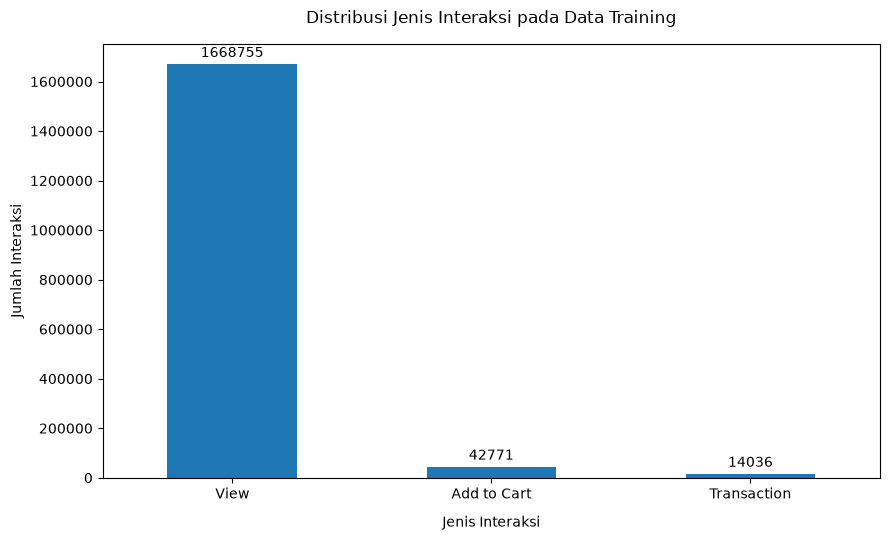

In [26]:

event_counts = (
    train_df["event"]
    .value_counts()
    .reindex(["view", "addtocart", "transaction"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5.5))

event_counts.plot(kind="bar", ax=ax)

ax.set_title(
    "Distribusi Jenis Interaksi pada Data Training",
    pad=15
)
ax.set_xlabel("Jenis Interaksi", labelpad=10)
ax.set_ylabel("Jumlah Interaksi")
ax.set_xticklabels(
    ["View", "Add to Cart", "Transaction"],
    rotation=0
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.ticklabel_format(axis="y", style="plain")

fig.tight_layout()
plt.show()


Interpretasi grafik : 

- View: 1.668.755 interaksi, paling dominan.
- Add to Cart: 42.771 interaksi.
- Transaction: 14.036 interaksi.

Ini menunjukkan bahwa aktivitas pengguna didominasi oleh melihat produk. Jumlah aktivitas memasukkan produk ke keranjang jauh lebih sedikit, dan jumlah transaksi lebih sedikit lagi.

5. Pembuatan VSM 

In [27]:
# Membentuk matriks interaksi Visitor-Item
user_item = train_df[["visitorid", "itemid"]].drop_duplicates()

visitor_ids = user_item["visitorid"].unique()
item_ids = user_item["itemid"].unique()

visitor_to_idx = {v: i for i, v in enumerate(visitor_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

rows = user_item["visitorid"].map(visitor_to_idx).to_numpy()
cols = user_item["itemid"].map(item_to_idx).to_numpy()
values = np.ones(len(user_item), dtype=np.uint8)

# VSM User: baris = visitor, kolom = item
vsm_user = csr_matrix(
    (values, (rows, cols)),
    shape=(len(visitor_ids), len(item_ids)),
    dtype=np.uint8
)

print("=== VSM USER ===")
print("Dimensi matriks:", vsm_user.shape)
print("Jumlah pasangan interaksi unik:", f"{vsm_user.nnz:,}")
print("Tipe matriks:", type(vsm_user).__name__)
print("Tipe data elemen:", vsm_user.dtype)

density = vsm_user.nnz / (
    vsm_user.shape[0] * vsm_user.shape[1]
) * 100
print(f"Kepadatan matriks: {density:.8f}%")

# VSM Item: baris = item, kolom = visitor
vsm_item = vsm_user.transpose().tocsr()

print("\n=== VSM ITEM ===")
print("Dimensi matriks:", vsm_item.shape)
print("Jumlah pasangan interaksi unik:", f"{vsm_item.nnz:,}")
print("Tipe matriks:", type(vsm_item).__name__)
print("Tipe data elemen:", vsm_item.dtype)

density_item = vsm_item.nnz / (
    vsm_item.shape[0] * vsm_item.shape[1]
) * 100
print(f"Kepadatan matriks: {density_item:.8f}%")


=== VSM USER ===
Dimensi matriks: (876860, 192581)
Jumlah pasangan interaksi unik: 1,336,552
Tipe matriks: csr_matrix
Tipe data elemen: uint8
Kepadatan matriks: 0.00079148%

=== VSM ITEM ===
Dimensi matriks: (192581, 876860)
Jumlah pasangan interaksi unik: 1,336,552
Tipe matriks: csr_matrix
Tipe data elemen: uint8
Kepadatan matriks: 0.00079148%


In [ ]:
# Perbandingan karakteristik VSM User dan VSM Item

comparison = pd.DataFrame({
    "Karakteristik": [
        "Jumlah entitas (baris)",
        "Jumlah fitur (kolom)",
        "Jumlah pasangan interaksi nonzero",
        "Jumlah elemen matriks",
        "Kepadatan (%)"
    ],
    "VSM User": [
        vsm_user.shape[0],
        vsm_user.shape[1],
        vsm_user.nnz,
        vsm_user.shape[0] * vsm_user.shape[1],
        vsm_user.nnz / (vsm_user.shape[0] * vsm_user.shape[1]) * 100
    ],
    "VSM Item": [
        vsm_item.shape[0],
        vsm_item.shape[1],
        vsm_item.nnz,
        vsm_item.shape[0] * vsm_item.shape[1],
        vsm_item.nnz / (vsm_item.shape[0] * vsm_item.shape[1]) * 100
    ]
})

display(comparison)

print(
    "Rasio jumlah entitas User terhadap Item:",
    round(vsm_user.shape[0] / vsm_item.shape[0], 2),
    "kali"
)


,Karakteristik,VSM User,VSM Item
0,Jumlah entitas (baris),8.768600e+05,1.925810e+05
1,Jumlah fitur (kolom),1.925810e+05,8.768600e+05
2,Jumlah pasangan interaksi nonzero,1.336552e+06,1.336552e+06
3,Jumlah elemen matriks,1.688666e+11,1.688666e+11
4,Kepadatan (%),7.914840e-04,7.914840e-04


Rasio jumlah entitas User terhadap Item: 4.55 kali


6. Analisis Pemilihan Proyeksi User dan Item

Berdasarkan hasil Vector Space Modelling (VSM), matriks VSM User memiliki dimensi 876.860 × 192.581, sedangkan matriks VSM Item memiliki dimensi 192.581 × 876.860. Kedua matriks mempunyai 1.336.552 pasangan interaksi nonzero dengan tingkat kepadatan sekitar 0,00079148%. Hal ini menunjukkan bahwa data interaksi bersifat sangat sparse.

Dari sisi efisiensi, VSM Item memiliki jumlah baris sekitar 4,55 kali lebih sedikit daripada VSM User. Kondisi ini menguntungkan ketika analisis difokuskan pada pencarian item yang memiliki pola interaksi serupa. Sebaliknya, VSM User lebih sesuai apabila tujuan analisis adalah mencari pengguna dengan perilaku interaksi yang mirip.

Pada tugas ini, proyeksi Item dipilih karena analisis berikutnya berfokus pada perhitungan cosine similarity antara satu item acuan dan item lainnya. Pemilihan ini sesuai dengan tujuan pencarian item serupa serta mengurangi jumlah entitas yang perlu dipertimbangkan dibandingkan proyeksi User. Meskipun demikian, efisiensi aktual juga dipengaruhi oleh sparsity matriks, jumlah interaksi, dan metode perhitungan similarity yang digunakan.

Dengan demikian, proyeksi Item dinilai lebih sesuai untuk kebutuhan analisis pada tugas ini, bukan berarti selalu lebih unggul untuk semua jenis analisis graf.


6. Visualisasi dengan Networkx (dengan sample)

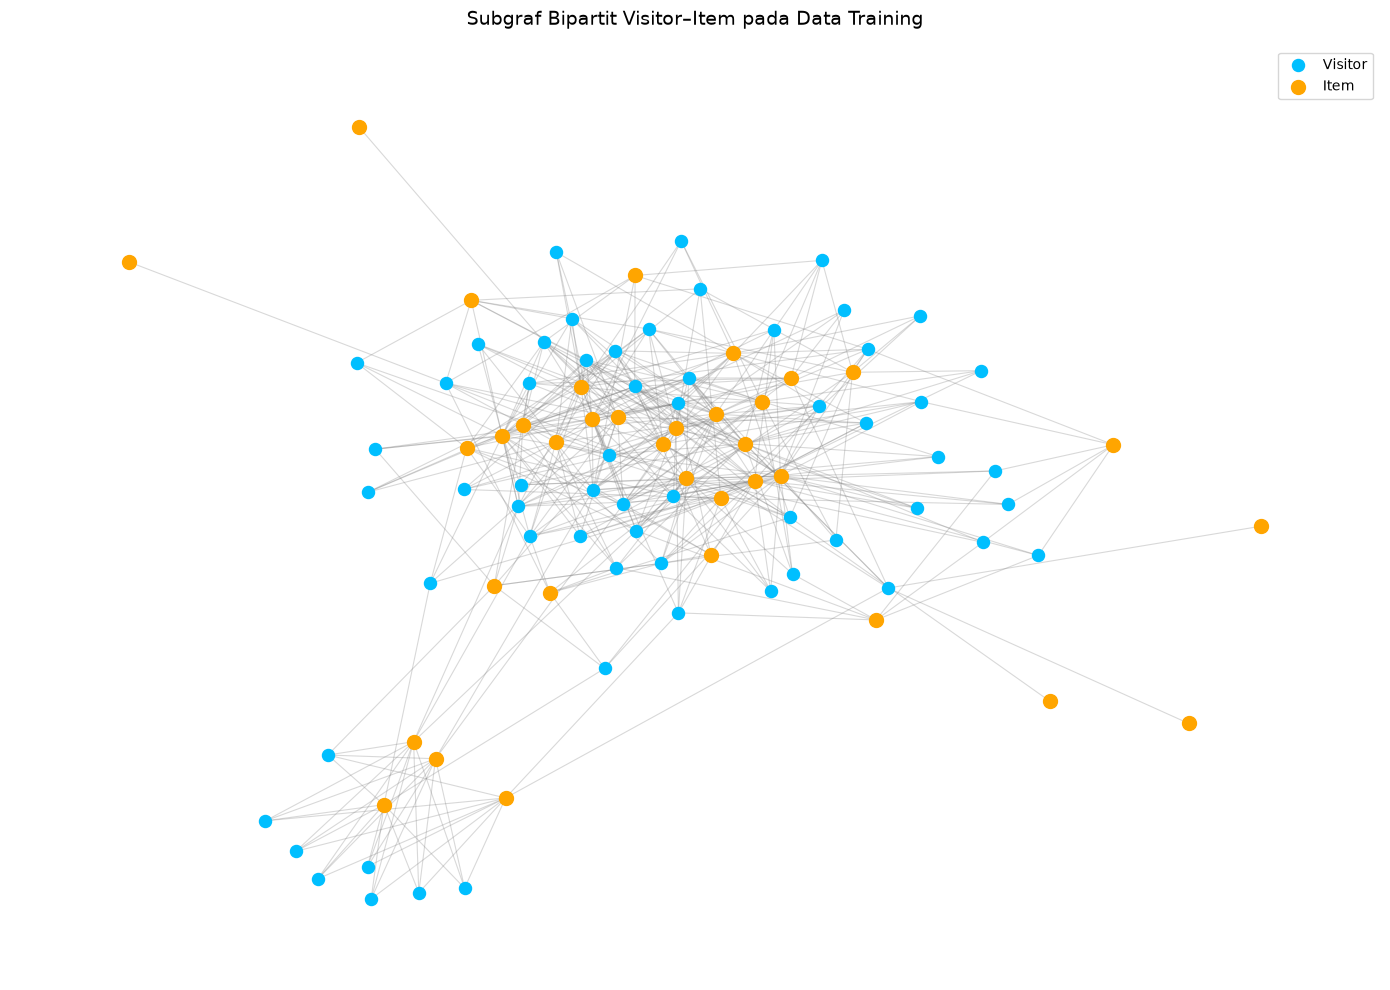

=== KARAKTERISTIK SUBGRAF ===
Jumlah Visitor: 60
Jumlah Item: 35
Jumlah simpul: 95
Jumlah sisi: 404
Graf bipartit: True
Komponen terhubung: 1
Item awal terpilih: 40
Pasangan interaksi dalam subgraf: 404


In [ ]:

# SUBGRAF BIPARTIT VISITOR-ITEM

# 1. Pasangan Visitor-Item unik dari data Training
pairs = train_df[["visitorid", "itemid"]].drop_duplicates()

# 2. Hitung jumlah visitor unik untuk setiap item
item_degree = pairs.groupby("itemid")["visitorid"].nunique()

# 3. Pilih maksimal 40 item dengan minimal 3 visitor
selected_items = (
    item_degree[item_degree >= 3]
    .sort_values(ascending=False)
    .head(40)
    .index
)

# 4. Ambil hubungan visitor-item pada item terpilih
sub_pairs = pairs[pairs["itemid"].isin(selected_items)].copy()

# 5. Batasi maksimal 60 visitor dengan interaksi terbanyak
selected_visitors = (
    sub_pairs["visitorid"]
    .value_counts()
    .head(60)
    .index
)

sub_pairs = sub_pairs[
    sub_pairs["visitorid"].isin(selected_visitors)
].copy()

# 6. Bentuk graf bipartit
G_sub = nx.Graph()

for row in sub_pairs.itertuples(index=False):
    visitor = f"V_{row.visitorid}"
    item = f"I_{row.itemid}"

    G_sub.add_node(visitor, node_type="Visitor", bipartite=0)
    G_sub.add_node(item, node_type="Item", bipartite=1)
    G_sub.add_edge(visitor, item)

# 7. Pisahkan simpul berdasarkan jenisnya
visitor_nodes = [
    n for n, d in G_sub.nodes(data=True)
    if d["node_type"] == "Visitor"
]

item_nodes = [
    n for n, d in G_sub.nodes(data=True)
    if d["node_type"] == "Item"
]

# 8. Posisi simpul
pos = nx.spring_layout(
    G_sub,
    seed=42,
    k=0.6,
    iterations=100
)

# 9. Visualisasi
fig, ax = plt.subplots(figsize=(14, 10))

nx.draw_networkx_edges(
    G_sub, pos,
    ax=ax,
    edge_color="gray",
    alpha=0.3,
    width=0.8
)

nx.draw_networkx_nodes(
    G_sub, pos,
    nodelist=visitor_nodes,
    node_color="deepskyblue",
    node_size=75,
    label="Visitor",
    ax=ax
)

nx.draw_networkx_nodes(
    G_sub, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=100,
    label="Item",
    ax=ax
)

ax.set_title(
    "Subgraf Bipartit Visitor–Item pada Data Training",
    fontsize=14,
    pad=15
)
ax.legend()
ax.axis("off")
fig.tight_layout()
plt.show()

# 10. Karakteristik subgraf
print("=== KARAKTERISTIK SUBGRAF ===")
print("Jumlah Visitor:", len(visitor_nodes))
print("Jumlah Item:", len(item_nodes))
print("Jumlah simpul:", G_sub.number_of_nodes())
print("Jumlah sisi:", G_sub.number_of_edges())
print("Graf bipartit:", nx.is_bipartite(G_sub))
print("Komponen terhubung:", nx.number_connected_components(G_sub))
print("Item awal terpilih:", len(selected_items))
print("Pasangan interaksi dalam subgraf:", len(sub_pairs))


Visualisasi dan Karakteristik Subgraf Bipartit

Visualisasi graf bipartit dibentuk dari data training RetailRocket dengan memilih 40 item yang memiliki interaksi dengan minimal tiga visitor, kemudian membatasi jaringan pada 60 visitor dengan interaksi terbanyak. Setelah proses penyaringan, terbentuk subgraf yang terdiri atas 60 simpul Visitor dan 35 simpul Item, sehingga totalnya 95 simpul dengan 404 sisi. Hasil pemeriksaan menunjukkan bahwa graf bersifat bipartit dan memiliki satu komponen terhubung. Perbedaan antara 40 item yang dipilih pada tahap awal dan 35 item yang muncul pada graf disebabkan oleh penyaringan visitor, sehingga beberapa item tidak lagi memiliki hubungan pada subgraf akhir. Visualisasi ini memperlihatkan pola hubungan antara pengguna dan produk secara lebih terfokus.

7. Menghitung smilarity berdasarkan sample

In [29]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Pilih maksimal 100 visitor pertama untuk contoh perhitungan
n_users = min(100, vsm_user.shape[0])
vsm_user_sample = vsm_user[:n_users]

# Hitung Cosine Similarity antarvisitor
user_similarity = cosine_similarity(
    vsm_user_sample,
    dense_output=False
)

print("=== USER SIMILARITY ===")
print("Dimensi:", user_similarity.shape)
print("Tipe matriks:", type(user_similarity).__name__)
print("Jumlah nilai similarity nonzero:", user_similarity.nnz)


=== USER SIMILARITY ===
Dimensi: (100, 100)
Tipe matriks: csr_matrix
Jumlah nilai similarity nonzero: 106


In [30]:
# Pilih maksimal 100 item pertama
n_items = min(100, vsm_item.shape[0])
vsm_item_sample = vsm_item[:n_items]

# Hitung Cosine Similarity antaritem
item_similarity = cosine_similarity(
    vsm_item_sample,
    dense_output=False
)

print("=== ITEM SIMILARITY ===")
print("Dimensi:", item_similarity.shape)
print("Tipe matriks:", type(item_similarity).__name__)
print("Jumlah nilai similarity nonzero:", item_similarity.nnz)


=== ITEM SIMILARITY ===
Dimensi: (100, 100)
Tipe matriks: csr_matrix
Jumlah nilai similarity nonzero: 438


In [31]:
# Menampilkan pasangan visitor dengan similarity tertinggi
user_sim_dense = user_similarity.toarray()

user_pairs = []

for i in range(user_sim_dense.shape[0]):
    for j in range(i + 1, user_sim_dense.shape[1]):
        score = user_sim_dense[i, j]

        if score > 0:
            user_pairs.append((i, j, score))

user_pairs = sorted(
    user_pairs,
    key=lambda x: x[2],
    reverse=True
)

print("=== TOP 10 USER SIMILARITY ===")
for user_a, user_b, score in user_pairs[:10]:
    print(
        f"Visitor indeks {user_a} dan {user_b}: "
        f"similarity = {score:.4f}"
    )


=== TOP 10 USER SIMILARITY ===
Visitor indeks 10 dan 19: similarity = 1.0000
Visitor indeks 46 dan 70: similarity = 0.5774
Visitor indeks 24 dan 36: similarity = 0.2673


In [32]:

# Menampilkan pasangan item dengan similarity tertinggi
item_sim_dense = item_similarity.toarray()

item_pairs = []

for i in range(item_sim_dense.shape[0]):
    for j in range(i + 1, item_sim_dense.shape[1]):
        score = item_sim_dense[i, j]

        if score > 0:
            item_pairs.append((i, j, score))

item_pairs = sorted(
    item_pairs,
    key=lambda x: x[2],
    reverse=True
)

print("=== TOP 10 ITEM SIMILARITY ===")
for item_a, item_b, score in item_pairs[:10]:
    print(
        f"Item indeks {item_a} dan {item_b}: "
        f"similarity = {score:.4f}"
    )


=== TOP 10 ITEM SIMILARITY ===
Item indeks 12 dan 85: similarity = 0.3419
Item indeks 86 dan 88: similarity = 0.3162
Item indeks 45 dan 72: similarity = 0.1373
Item indeks 45 dan 49: similarity = 0.1369
Item indeks 28 dan 65: similarity = 0.1291
Item indeks 49 dan 72: similarity = 0.1228
Item indeks 18 dan 91: similarity = 0.1177
Item indeks 1 dan 42: similarity = 0.1054
Item indeks 0 dan 42: similarity = 0.0803
Item indeks 42 dan 53: similarity = 0.0645


In [33]:
# Pemetaan indeks ke ID asli
visitor_ids_sample = visitor_ids[:n_users]
item_ids_sample = item_ids[:n_items]

print("=== TOP USER SIMILARITY DENGAN ID ASLI ===")
for i, j, score in user_pairs[:10]:
    print(
        f"Visitor ID {visitor_ids_sample[i]} "
        f"dan Visitor ID {visitor_ids_sample[j]}: "
        f"similarity = {score:.4f}"
    )

print("\n=== TOP ITEM SIMILARITY DENGAN ID ASLI ===")
for i, j, score in item_pairs[:10]:
    print(
        f"Item ID {item_ids_sample[i]} "
        f"dan Item ID {item_ids_sample[j]}: "
        f"similarity = {score:.4f}"
    )


=== TOP USER SIMILARITY DENGAN ID ASLI ===
Visitor ID 176446 dan Visitor ID 158090: similarity = 1.0000
Visitor ID 392042 dan Visitor ID 721839: similarity = 0.5774
Visitor ID 125625 dan Visitor ID 112175: similarity = 0.2673

=== TOP ITEM SIMILARITY DENGAN ID ASLI ===
Item ID 44872 dan Item ID 81075: similarity = 0.3419
Item ID 257675 dan Item ID 328025: similarity = 0.3162
Item ID 280375 dan Item ID 391289: similarity = 0.1373
Item ID 280375 dan Item ID 16813: similarity = 0.1369
Item ID 388242 dan Item ID 357579: similarity = 0.1291
Item ID 16813 dan Item ID 391289: similarity = 0.1228
Item ID 176721 dan Item ID 261865: similarity = 0.1177
Item ID 248676 dan Item ID 386527: similarity = 0.1054
Item ID 355908 dan Item ID 386527: similarity = 0.0803
Item ID 386527 dan Item ID 134264: similarity = 0.0645


Analisis Cosine Similarity pada Graf Bipartit Visitor–Item : 

Perhitungan Cosine Similarity dilakukan menggunakan representasi VSM User dan VSM Item yang dibangun dari data training RetailRocket. Pada sampel 100 visitor, pasangan visitor dengan ID 176446 dan 158090 memperoleh nilai similarity tertinggi sebesar 1,0000. Hasil ini menunjukkan bahwa keduanya memiliki pola interaksi yang identik dalam representasi VSM. Sementara itu, pasangan visitor 392042 dan 721839 memperoleh nilai 0,5774, sedangkan pasangan 125625 dan 112175 memperoleh nilai 0,2673.

Pada analisis kemiripan item, pasangan item 44872 dan 81075 memperoleh nilai tertinggi sebesar 0,3419, diikuti item 257675 dan 328025 sebesar 0,3162. Hasil ini menunjukkan adanya kesamaan pola visitor pada pasangan item tersebut. Analisis ini dapat menjadi dasar untuk memahami kemiripan perilaku pengguna dan keterkaitan item berdasarkan riwayat interaksi.

8. Top 5 Simlarity

In [35]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

# 1. Hitung jumlah visitor unik yang berinteraksi dengan setiap item
item_degrees = np.asarray(vsm_item.getnnz(axis=1)).ravel()

# 2. Pilih item acuan secara konsisten:
# item dengan jumlah visitor terbanyak
anchor_idx = int(item_degrees.argmax())
anchor_item_id = int(item_ids[anchor_idx])

# 3. Hitung cosine similarity item acuan terhadap seluruh item
similarity_scores = cosine_similarity(
    vsm_item[anchor_idx],
    vsm_item,
    dense_output=False
).toarray().ravel()

# 4. Keluarkan item acuan dari kandidat
similarity_scores[anchor_idx] = 0.0

# 5. Ambil 5 item lain dengan similarity tertinggi
candidate_indices = np.flatnonzero(similarity_scores > 0)

top_indices = candidate_indices[
    np.argsort(similarity_scores[candidate_indices])[::-1][:5]
]

# 6. Buat tabel hasil
top5_items = pd.DataFrame({
    "anchor_item_id": anchor_item_id,
    "similar_item_id": [
        int(item_ids[i]) for i in top_indices
    ],
    "similarity": [
        float(similarity_scores[i]) for i in top_indices
    ],
    "shared_visitors": [
        int(
            vsm_item[anchor_idx]
            .multiply(vsm_item[i]).nnz
        )
        for i in top_indices
    ]
})

print("Item acuan:", anchor_item_id)
print("Jumlah visitor item acuan:", int(item_degrees[anchor_idx]))
print("Jumlah item serupa ditemukan:", len(top5_items))

display(top5_items)


Item acuan: 5411
Jumlah visitor item acuan: 1679
Jumlah item serupa ditemukan: 5


,anchor_item_id,similar_item_id,similarity,shared_visitors
0,5411,33030,0.137343,68
1,5411,33956,0.080941,22
2,5411,358234,0.080113,25
3,5411,37807,0.073341,17
4,5411,375492,0.063693,38


9. Simpan Top 5 ke Neo4J

 => Kode Koneksi Driver

In [37]:

from neo4j import GraphDatabase
import os
from getpass import getpass

NEO4J_URI = "neo4j://127.0.0.1:7687"
NEO4J_USER = "neo4j"

NEO4J_PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USER, NEO4J_PASSWORD)
)

# Uji koneksi
driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_5936\926077886.py:16: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [38]:
# Simpan 5 hasil cosine similarity ke graf Neo4j

records = top5_items.to_dict(orient="records")

cypher_save = """
UNWIND $records AS row
MATCH (anchor:Item {itemid: row.anchor_item_id})
MATCH (other:Item {itemid: row.similar_item_id})
MERGE (anchor)-[s:SIMILAR_TO]->(other)
SET s.similarity = row.similarity,
    s.sharedVisitors = row.shared_visitors,
    s.method = 'Cosine Similarity',
    s.period = 'P1 Training'
RETURN anchor.itemid AS item_acuan,
       other.itemid AS item_serupa,
       s.similarity AS similarity,
       s.sharedVisitors AS shared_visitors
ORDER BY similarity DESC
"""

with driver.session(database="neo4j") as session:
    saved_rows = [
        record.data()
        for record in session.run(cypher_save, records=records)
    ]

saved_df = pd.DataFrame(saved_rows)
display(saved_df)

print("Jumlah relasi yang ditampilkan:", len(saved_df))


,item_acuan,item_serupa,similarity,shared_visitors
0,5411,33030,0.137343,68
1,5411,33956,0.080941,22
2,5411,358234,0.080113,25
3,5411,37807,0.073341,17
4,5411,375492,0.063693,38


Jumlah relasi yang ditampilkan: 5


## 2.2 Analytics (Maks. skor: 55)

No. 1 A & B

In [ ]:
import numpy as np
import pandas as pd

# Ambil visitor yang muncul di data training dan testing
train_visitors = set(train_df["visitorid"].unique())
test_visitors = set(test_df["visitorid"].unique())

eligible_visitors = np.array(
    sorted(train_visitors.intersection(test_visitors))
)

# Pilih satu visitor secara acak dengan seed tetap
SEED = 42
rng = np.random.default_rng(SEED)

target_visitor = int(rng.choice(eligible_visitors))

# Riwayat interaksi pada P1
target_train = train_df[
    train_df["visitorid"] == target_visitor
]

# Interaksi aktual pada P2 untuk evaluasi
target_test = test_df[
    test_df["visitorid"] == target_visitor
]

print("Random seed:", SEED)
print("Jumlah visitor yang memenuhi syarat:", len(eligible_visitors))
print("Visitor terpilih:", target_visitor)
print("Jumlah interaksi P1:", len(target_train))
print("Jumlah interaksi P2:", len(target_test))
print(
    "Jumlah item unik P1:",
    target_train["itemid"].nunique()
)
print(
    "Jumlah item unik P2:",
    target_test["itemid"].nunique()
)

# Cari target yang menghasilkan minimal 3 rekomendasi
# dengan tetap menggunakan KNN k=5

from sklearn.neighbors import NearestNeighbors
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)

# Kandidat: minimal 5 item unik di P1 dan memiliki interaksi P2
train_item_counts = train_df.groupby("visitorid")["itemid"].nunique()
test_item_counts = test_df.groupby("visitorid")["itemid"].nunique()

eligible = train_item_counts[train_item_counts >= 5].index
eligible = eligible.intersection(
    test_item_counts[test_item_counts >= 1].index
)
eligible = np.array(sorted(eligible))

# Acak urutan kandidat secara reproducible
shuffled_candidates = rng.permutation(eligible)

# Model KNN: k=5 tetangga selain target
knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(interaction_matrix)

# Siapkan item per visitor agar pencarian lebih efisien
items_by_visitor = (
    train_pairs.groupby("visitorid")["itemid"]
    .agg(set)
    .to_dict()
)

target_visitor = None
recommendations = pd.DataFrame()
neighbors = []

for candidate in shuffled_candidates:
    candidate = int(candidate)
    target_idx = visitor_to_idx[candidate]

    # Ambil 6 tetangga: target sendiri + 5 tetangga lain
    distances, indices = knn.kneighbors(
        interaction_matrix[target_idx],
        n_neighbors=6
    )

    neighbors_candidate = [
        (idx, dist)
        for idx, dist in zip(indices[0], distances[0])
        if int(all_visitors[idx]) != candidate
    ][:5]

    seen = items_by_visitor.get(candidate, set())
    scores = {}

    for neighbor_idx, distance in neighbors_candidate:
        neighbor_id = int(all_visitors[neighbor_idx])
        similarity = max(0.0, 1.0 - float(distance))

        for item in items_by_visitor.get(neighbor_id, set()) - seen:
            scores[item] = scores.get(item, 0.0) + similarity

    ranked = sorted(scores.items(), key=lambda x: (-x[1], x[0]))

    if len(ranked) >= 5:
        target_visitor = candidate
        neighbors = neighbors_candidate
        recommendations = pd.DataFrame(
            ranked,
            columns=["itemid", "recommendation_score"]
        )
        break

if target_visitor is None:
    print("Belum ditemukan target dengan minimal 3 rekomendasi.")
else:
    target_train = train_df[train_df["visitorid"] == target_visitor]
    target_test = test_df[test_df["visitorid"] == target_visitor]

    print("Random seed:", SEED)
    print("Visitor target:", target_visitor)
    print("Item unik P1:", target_train["itemid"].nunique())
    print("Item unik P2:", target_test["itemid"].nunique())
    print("Jumlah tetangga:", len(neighbors))
    print("Jumlah kandidat rekomendasi:", len(recommendations))
    print("\nTiga rekomendasi teratas:")
    display(recommendations.head(3))



Random seed: 42
Jumlah visitor yang memenuhi syarat: 32267
Visitor terpilih: 127183
Jumlah interaksi P1: 3
Jumlah interaksi P2: 3
Jumlah item unik P1: 3
Jumlah item unik P2: 3
Random seed: 42
Visitor target: 1023158
Item unik P1: 10
Item unik P2: 1
Jumlah tetangga: 5
Jumlah kandidat rekomendasi: 7

Tiga rekomendasi teratas:


,itemid,recommendation_score
0,351530,0.965685
1,209048,0.765148
2,100653,0.400000


No. 2 A & B

In [48]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix
import numpy as np
import pandas as pd

# Bentuk matriks interaksi dari P1
train_pairs = train_df[["visitorid", "itemid"]].drop_duplicates()

all_visitors = train_pairs["visitorid"].unique()
all_items = train_pairs["itemid"].unique()

visitor_to_idx = {
    visitor: idx for idx, visitor in enumerate(all_visitors)
}
item_to_idx = {
    item: idx for idx, item in enumerate(all_items)
}

row_idx = train_pairs["visitorid"].map(visitor_to_idx).to_numpy()
col_idx = train_pairs["itemid"].map(item_to_idx).to_numpy()

interaction_matrix = csr_matrix(
    (
        np.ones(len(train_pairs), dtype=np.float32),
        (row_idx, col_idx)
    ),
    shape=(len(all_visitors), len(all_items))
)

# Pastikan target terdapat dalam matriks
if target_visitor not in visitor_to_idx:
    raise ValueError("Target tidak ditemukan dalam data training.")

# Model KNN dengan lima tetangga selain target
knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(interaction_matrix)

target_idx = visitor_to_idx[target_visitor]

distances, indices = knn.kneighbors(
    interaction_matrix[target_idx],
    n_neighbors=6
)

neighbors = [
    (idx, dist)
    for idx, dist in zip(indices[0], distances[0])
    if int(all_visitors[idx]) != target_visitor
][:5]

items_by_visitor = (
    train_pairs.groupby("visitorid")["itemid"].agg(set).to_dict()
)

seen_items = items_by_visitor.get(target_visitor, set())
scores = {}

for neighbor_idx, distance in neighbors:
    neighbor_id = int(all_visitors[neighbor_idx])
    similarity = max(0.0, 1.0 - float(distance))

    neighbor_items = items_by_visitor.get(neighbor_id, set())

    for item in neighbor_items - seen_items:
        scores[item] = scores.get(item, 0.0) + similarity

ranked = sorted(scores.items(), key=lambda x: (-x[1], x[0]))

recommendations = pd.DataFrame(
    ranked,
    columns=["itemid", "recommendation_score"]
)

print("Target visitor:", target_visitor)
print("Jumlah tetangga:", len(neighbors))
print("Jumlah kandidat rekomendasi:", len(recommendations))
display(recommendations.head(5))

Target visitor: 1023158
Jumlah tetangga: 5
Jumlah kandidat rekomendasi: 7


,itemid,recommendation_score
0,351530,0.965685
1,209048,0.765148
2,100653,0.400000
3,324636,0.400000
4,401759,0.400000


In [49]:
import numpy as np

# Item aktual visitor pada periode testing (P2)
relevant_items = set(
    test_df.loc[
        test_df["visitorid"] == target_visitor,
        "itemid"
    ].unique()
)

# Lima rekomendasi teratas
top5 = recommendations.head(5)["itemid"].tolist()

# Relevansi setiap rekomendasi: 1 = relevan, 0 = tidak relevan
relevance = [
    int(item in relevant_items)
    for item in top5
]

# Hit@5
hit_at_5 = float(any(relevance))

# DCG@5
dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(relevance, start=1)
)

# IDCG@5
ideal_relevance = [1] * min(len(relevant_items), 5)

idcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(ideal_relevance, start=1)
)

# NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("Target visitor:", target_visitor)
print("Item relevan pada P2:", len(relevant_items))
print("Lima rekomendasi:", top5)
print("Relevansi:", relevance)
print(f"Hit@5: {hit_at_5:.4f}")
print(f"NDCG@5: {ndcg_at_5:.4f}")

Target visitor: 1023158
Item relevan pada P2: 1
Lima rekomendasi: [351530, 209048, 100653, 324636, 401759]
Relevansi: [0, 0, 0, 0, 0]
Hit@5: 0.0000
NDCG@5: 0.0000


In [50]:
actual_items = sorted(
    test_df.loc[
        test_df["visitorid"] == target_visitor,
        "itemid"
    ].unique()
)

print("Target visitor:", target_visitor)
print("Item aktual P2:", actual_items)
print("Lima rekomendasi:", top5)

print(
    "Irisan item aktual dan rekomendasi:",
    sorted(set(actual_items) & set(top5))
)

Target visitor: 1023158
Item aktual P2: [np.int64(195473)]
Lima rekomendasi: [351530, 209048, 100653, 324636, 401759]
Irisan item aktual dan rekomendasi: []
